# TrustWave Bank — EDA and Feature Engineering
## DS Sprint Skill-Based Assessment — Round 1 (EDA Phase)

**Organisation:** TrustWave Bank (Banking Sector)  
**Business Question:** How do customers use banking services, and which customer segments show changing engagement?  
**Data Period:** January 2022 – December 2024 (3 years)

---

### Dataset Mapping

| Assessment Dataset | Actual File Used | Role |
|--------------------|-----------------|------|
| customers.csv | dim_customers.csv | Age band, region, relationship length, segment |
| accounts.csv | dim_accounts.csv | Account type, balance |
| transactions.csv | fact_transactions.csv | Date, amount, transaction type, channel |
| channels.csv | fact_transactions.csv (channel column) | Bank Transfer/ATM/Mobile/Online/POS usage |
| service.csv | fact_complaints.csv | Requests, complaints, resolution |

> **Note:** The assessment specifies five separate CSV files. The actual available data is structured as a Star Schema with nine CSVs. All five assessment datasets are fully available from these nine files via the column mappings shown above. No required fields are missing.

---

### Table of Contents
1. Setup and Library Imports
2. Data Loading and Initial Inspection
3. Data Preprocessing and Cleaning
4. EDA Q1: Which channels are used most?
5. EDA Q2: How does channel use differ by age band?
6. EDA Q3: Which account types show declining activity?
7. EDA Q4: Which regions generate more complaints?
8. EDA Q5: How do balances differ by segment?
9. EDA Q6: Which services drive repeated requests?
10. Feature Engineering
11. Feature Selection and Encoding
12. Summary of Findings and Limitations

---
## 1. Setup and Library Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.figsize': (10, 5)})

print('Libraries loaded.')
print(f'Pandas: {pd.__version__} | NumPy: {np.__version__} | Seaborn: {sns.__version__}')

Libraries loaded.
Pandas: 2.2.3 | NumPy: 2.1.3 | Seaborn: 0.13.2


---
## 2. Data Loading and Initial Inspection

We load all nine CSV files from the cleaned data directory, display shape, column names, data types, first five rows, and descriptive statistics.

In [2]:
# Adjust BASE_PATH if you run this notebook from a different directory
BASE_PATH = os.path.join(os.getcwd(), 'Data', 'Cleaned', 'Cleaned')
print('Loading from:', BASE_PATH)
print('Files found:', os.listdir(BASE_PATH))

Loading from: c:\Users\vimal\Downloads\Banking-Analytics-Project\Banking-Analytics-Project-main\Data\Cleaned\Cleaned
Files found: ['dim_accounts.csv', 'dim_branches.csv', 'dim_cards.csv', 'dim_customers.csv', 'dim_date.csv', 'dim_merchants.csv', 'fact_complaints.csv', 'fact_loans.csv', 'fact_transactions.csv']


In [3]:
customers    = pd.read_csv(os.path.join(BASE_PATH, 'dim_customers.csv'))
accounts     = pd.read_csv(os.path.join(BASE_PATH, 'dim_accounts.csv'))
transactions = pd.read_csv(os.path.join(BASE_PATH, 'fact_transactions.csv'))
complaints   = pd.read_csv(os.path.join(BASE_PATH, 'fact_complaints.csv'))
branches     = pd.read_csv(os.path.join(BASE_PATH, 'dim_branches.csv'))
cards        = pd.read_csv(os.path.join(BASE_PATH, 'dim_cards.csv'))
merchants    = pd.read_csv(os.path.join(BASE_PATH, 'dim_merchants.csv'))
loans        = pd.read_csv(os.path.join(BASE_PATH, 'fact_loans.csv'))
dim_date     = pd.read_csv(os.path.join(BASE_PATH, 'dim_date.csv'))

datasets = {
    'customers': customers, 'accounts': accounts,
    'transactions': transactions, 'complaints': complaints,
    'branches': branches, 'cards': cards,
    'merchants': merchants, 'loans': loans, 'dim_date': dim_date,
}

print(f'\n{"Dataset":<15} {"Rows":>10} {"Cols":>6}')
print('-' * 35)
for name, df in datasets.items():
    print(f'{name:<15} {len(df):>10,} {len(df.columns):>6}')


Dataset               Rows   Cols
-----------------------------------
customers          150,000     23
accounts           240,000     10
transactions     2,548,213     13
complaints          11,552     10
branches                25     12
cards              300,000      7
merchants            3,500      5
loans              120,000     12
dim_date             1,096     13


In [4]:
# Inspect each dataset: dtypes, first 5 rows, describe
for name, df in datasets.items():
    print('=' * 70)
    print(f'DATASET: {name.upper()}  |  Shape: {df.shape}')
    print(df.dtypes.to_string())
    print('\nFirst 5 rows:')
    display(df.head())
    print('\nDescriptive statistics:')
    display(df.describe())
    print()

DATASET: CUSTOMERS  |  Shape: (150000, 23)
customer_id                object
name                       object
age                         int64
gender                     object
occupation                 object
employment_type            object
education                  object
marital_status             object
income_bracket             object
monthly_income              int64
credit_score                int64
risk_category              object
customer_segment           object
kyc_status                 object
signup_date                object
city                       object
state                      object
home_branch_id             object
is_digital_banking_user      bool
is_upi_user                  bool
is_mobile_app_user           bool
sms_alerts_enabled           bool
is_insurance_holder          bool

First 5 rows:


,customer_id,name,age,gender,occupation,employment_type,education,marital_status,income_bracket,monthly_income,credit_score,risk_category,customer_segment,kyc_status,signup_date,city,state,home_branch_id,is_digital_banking_user,is_upi_user,is_mobile_app_user,sms_alerts_enabled,is_insurance_holder
0,CUST000001,Robert Garcia,41,Male,Salaried - Private,Part-Time,Bachelor's,Married,Middle,47167,711,Low Risk,New,Pending,2024-12-03,Delhi,Delhi,BR0001,False,True,True,False,True
1,CUST000002,Janice Petty,18,Male,Student,Not Employed,Diploma,Single,Lower-Middle,33909,612,Medium Risk,Regular,Verified,2022-09-27,Pune,Maharashtra,BR0010,True,True,True,False,False
2,CUST000003,Victor Waller,29,Female,Business Owner,Self-Employed,High School,Married,Middle,73005,719,Low Risk,Regular,Verified,2022-02-11,Kochi,Kerala,BR0008,True,True,True,True,False
3,CUST000004,Brenda Morrison,39,Female,Business Owner,Self-Employed,Master's,Married,Upper-Middle,137778,838,Low Risk,Premium,Verified,2023-11-08,Jaipur,Rajasthan,BR0004,True,True,True,True,False
4,CUST000005,Michael Valencia,28,Male,Salaried - Private,Full-Time,Bachelor's,Single,Middle,79537,653,Medium Risk,Regular,Verified,2024-05-11,Lucknow,Uttar Pradesh,BR0003,True,True,True,False,True



Descriptive statistics:


,age,monthly_income,credit_score
count,"150,000.00","150,000.00","150,000.00"
mean,39.76,"83,277.16",686.88
std,12.46,"76,732.53",90.77
min,18.00,"12,000.00",344.00
25%,31.00,"34,748.75",622.00
50%,40.00,"60,350.00",686.00
75%,48.00,"101,750.75",751.00
max,85.00,"399,965.00",900.00



DATASET: ACCOUNTS  |  Shape: (240000, 10)
account_id              object
customer_id             object
account_type            object
open_date               object
branch_id               object
status                  object
current_balance        float64
avg_monthly_balance    float64
min_balance            float64
interest_earned        float64

First 5 rows:


...

,loan_amount,interest_rate,tenure_months,emi,outstanding_balance,interest_income
count,"120,000.00","120,000.00","120,000.00","120,000.00","120,000.00","120,000.00"
mean,"1,532,151.58",10.82,81.37,"29,330.39","1,248,348.39","73,912.83"
std,"1,829,454.82",1.90,80.49,"31,766.86","1,722,022.38","137,316.52"
min,"20,038.10",7.00,6.00,650.10,0.00,0.00
25%,"359,761.01",9.21,30.00,"11,560.70","169,116.58","6,434.26"
50%,"706,270.54",10.53,51.00,"20,322.82","488,319.74","23,850.60"
75%,"1,856,252.50",12.71,97.00,"36,651.64","1,486,459.39","74,768.76"
max,"7,999,246.40",14.92,360.00,"443,112.86","7,988,774.88","2,896,620.37"



DATASET: DIM_DATE  |  Shape: (1096, 13)
date_id            int64
full_date         object
day                int64
month              int64
month_name        object
year               int64
quarter            int64
financial_year    object
weekday_name      object
is_weekend          bool
is_festival         bool
is_salary_week      bool
is_holiday          bool

First 5 rows:


,date_id,full_date,day,month,month_name,year,quarter,financial_year,weekday_name,is_weekend,is_festival,is_salary_week,is_holiday
0,20220101,2022-01-01,1,1,January,2022,1,2021-22,Saturday,True,False,True,True
1,20220102,2022-01-02,2,1,January,2022,1,2021-22,Sunday,True,False,True,True
2,20220103,2022-01-03,3,1,January,2022,1,2021-22,Monday,False,False,True,False
3,20220104,2022-01-04,4,1,January,2022,1,2021-22,Tuesday,False,False,False,False
4,20220105,2022-01-05,5,1,January,2022,1,2021-22,Wednesday,False,False,False,False



Descriptive statistics:


,date_id,day,month,year,quarter
count,"1,096.00","1,096.00","1,096.00","1,096.00","1,096.00"
mean,"20,230,677.05",15.73,6.52,"2,023.00",2.51
std,"8,177.35",8.81,3.45,0.82,1.12
min,"20,220,101.00",1.00,1.00,"2,022.00",1.00
25%,"20,221,001.75",8.00,4.00,"2,022.00",2.00
50%,"20,230,702.50",16.00,7.00,"2,023.00",3.00
75%,"20,240,401.25",23.00,10.00,"2,024.00",4.00
max,"20,241,231.00",31.00,12.00,"2,024.00",4.00


In [5]:
# Missing value summary across all datasets
print('MISSING VALUES SUMMARY')
print('=' * 65)
for name, df in datasets.items():
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    if len(nulls) > 0:
        print(f'\n--- {name} ---')
        for col, n in nulls.items():
            print(f'  {col:<35} {n:>8,} missing ({n/len(df)*100:.1f}%)')
    else:
        print(f'--- {name}: No missing values ---')

MISSING VALUES SUMMARY
--- customers: No missing values ---
--- accounts: No missing values ---

--- transactions ---
  card_id                             1,348,213 missing (52.9%)
  merchant_id                           38,228 missing (1.5%)
  channel                               25,480 missing (1.0%)

--- complaints ---
  linked_transaction_id                  9,000 missing (77.9%)
  resolution_days                        1,641 missing (14.2%)
--- branches: No missing values ---
--- cards: No missing values ---
--- merchants: No missing values ---
--- loans: No missing values ---
--- dim_date: No missing values ---


**Missing Value Decisions:**

| Dataset | Column | Missing | Reason | Decision |
|---------|--------|---------|--------|----------|
| transactions | card_id | ~1.35M (53%) | Deposits and bank transfers have no card | Keep as-is — structurally valid |
| transactions | merchant_id | ~38K (1.5%) | Non-merchant transactions (salary) | Keep as-is — structurally valid |
| transactions | channel | ~25K (1%) | Channel not recorded | Fill with 'Unknown' |
| complaints | linked_transaction_id | 9,000 (78%) | Not all complaints link to a transaction | Keep as-is — structurally valid |
| complaints | resolution_days | 1,641 (14%) | Open / In-Progress complaints | Keep as-is — exclude from mean calculation |

---
## 3. Data Preprocessing and Cleaning

In [6]:
# 3.1 Record before-counts
before_counts = {name: len(df) for name, df in datasets.items()}
print('Record counts BEFORE cleaning:')
for k, v in before_counts.items():
    print(f'  {k:<15}: {v:>10,}')

Record counts BEFORE cleaning:
  customers      :    150,000
  accounts       :    240,000
  transactions   :  2,548,213
  complaints     :     11,552
  branches       :         25
  cards          :    300,000
  merchants      :      3,500
  loans          :    120,000
  dim_date       :      1,096


In [7]:
# 3.2 Duplicate transaction check
dup_full = transactions.duplicated().sum()
dup_id   = transactions['transaction_id'].duplicated().sum()
print(f'Full duplicate rows     : {dup_full:,}')
print(f'Duplicate transaction_id: {dup_id:,}')

transactions = transactions.drop_duplicates()
transactions = transactions.drop_duplicates(subset='transaction_id', keep='first')
print(f'Transactions after dedup: {len(transactions):,}')

Full duplicate rows     : 0
Duplicate transaction_id: 0
Transactions after dedup: 2,548,213


In [8]:
# 3.3 Standardise account labels
print('Before:', accounts['account_type'].unique())
accounts['account_type'] = accounts['account_type'].str.strip().str.title()
accounts['status']       = accounts['status'].str.strip().str.title()
print('After :', accounts['account_type'].unique())

Before: ['Credit' 'Savings' 'Current']
After : ['Credit' 'Savings' 'Current']


In [9]:
# 3.4 Fill channel NaN
print(f"Channel nulls before: {transactions['channel'].isnull().sum():,}")
transactions['channel'] = transactions['channel'].fillna('Unknown')
print(f"Channel nulls after : {transactions['channel'].isnull().sum():,}")

Channel nulls before: 25,480
Channel nulls after : 0


In [10]:
# 3.5 Parse dates
dim_date['full_date'] = pd.to_datetime(dim_date['full_date'])
transactions = transactions.merge(
    dim_date[['date_id', 'full_date', 'year', 'month', 'month_name', 'quarter']],
    on='date_id', how='left'
)
transactions['year_month']   = transactions['full_date'].dt.to_period('M').astype(str)
transactions['year_quarter'] = transactions['full_date'].dt.to_period('Q').astype(str)
customers['signup_date']     = pd.to_datetime(customers['signup_date'])

print('Dates parsed.')
print(f"Range: {transactions['full_date'].min()} to {transactions['full_date'].max()}")

Dates parsed.
Range: 2022-01-01 00:00:00 to 2024-12-31 00:00:00


Transaction Amount Statistics:
count     2,548,213.00
mean         58,766.12
std         332,700.57
min     -31,256,856.53
25%           2,508.29
50%          29,693.58
75%          67,845.51
max      44,259,194.65
Name: amount, dtype: float64


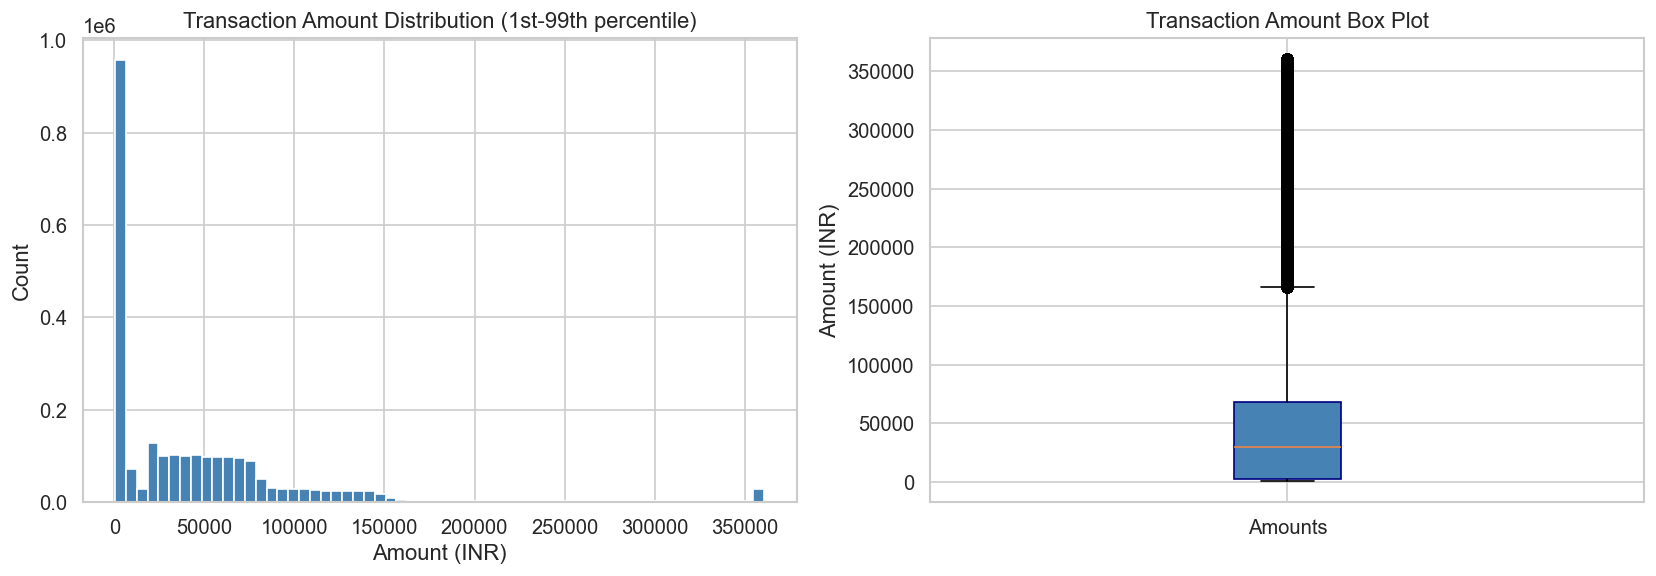

Negative amount rows: 12,736
Types with negatives: {'Deposit': 6899, 'Purchase': 3905, 'Transfer': 1084, 'Withdrawal': 848}


In [11]:
# 3.6 Inspect extreme transaction amounts
print('Transaction Amount Statistics:')
print(transactions['amount'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

p01 = transactions['amount'].quantile(0.01)
p99 = transactions['amount'].quantile(0.99)
clipped = transactions['amount'].clip(lower=p01, upper=p99)

axes[0].hist(clipped, bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('Transaction Amount Distribution (1st-99th percentile)')
axes[0].set_xlabel('Amount (INR)')
axes[0].set_ylabel('Count')

axes[1].boxplot(clipped, patch_artist=True,
                boxprops=dict(facecolor='steelblue', color='navy'))
axes[1].set_title('Transaction Amount Box Plot')
axes[1].set_ylabel('Amount (INR)')
axes[1].set_xticklabels(['Amounts'])

plt.tight_layout()
plt.savefig('amount_distribution.png', bbox_inches='tight')
plt.show()

# Negative amounts
neg = transactions[transactions['amount'] < 0]
print(f'Negative amount rows: {len(neg):,}')
print('Types with negatives:', neg['transaction_type'].value_counts().to_dict())

In [12]:
# 3.7 Outlier decision
Q1  = transactions['amount'].quantile(0.25)
Q3  = transactions['amount'].quantile(0.75)
IQR = Q3 - Q1
lo  = Q1 - 1.5 * IQR
hi  = Q3 + 1.5 * IQR
out = transactions[(transactions['amount'] < lo) | (transactions['amount'] > hi)]
print(f'IQR lower fence : {lo:>15,.2f}')
print(f'IQR upper fence : {hi:>15,.2f}')
print(f'Flagged outliers: {len(out):,} ({len(out)/len(transactions)*100:.1f}%)')
print('Decision: RETAIN all amounts. Negatives = legitimate withdrawals/reversals.')
print('Large positives = legitimate salary credits and large deposits.')

IQR lower fence :      -95,497.54
IQR upper fence :      165,851.34
Flagged outliers: 121,335 (4.8%)
Decision: RETAIN all amounts. Negatives = legitimate withdrawals/reversals.
Large positives = legitimate salary credits and large deposits.


In [13]:
# 3.8 Complaint missing value handling
print('Complaint nulls:')
print(complaints.isnull().sum())
resolved_complaints = complaints[complaints['status'] == 'Resolved'].copy()
print(f'\nTotal complaints  : {len(complaints):,}')
print(f'Resolved          : {len(resolved_complaints):,} ({len(resolved_complaints)/len(complaints)*100:.1f}%)')
print('linked_transaction_id NULLs kept — many complaints are not transaction-linked.')
print('resolution_days NULLs kept — these are unresolved complaints.')

Complaint nulls:
complaint_id                0
customer_id                 0
account_id                  0
linked_transaction_id    9000
date_id                     0
complaint_type              0
channel                     0
priority                    0
status                      0
resolution_days          1641
dtype: int64

Total complaints  : 11,552
Resolved          : 9,911 (85.8%)
linked_transaction_id NULLs kept — many complaints are not transaction-linked.
resolution_days NULLs kept — these are unresolved complaints.


In [14]:
# 3.9 Primary key and relationship validation
pk_checks = {
    'customers   (customer_id)' : customers['customer_id'].duplicated().sum(),
    'accounts    (account_id)'  : accounts['account_id'].duplicated().sum(),
    'transactions(txn_id)'      : transactions['transaction_id'].duplicated().sum(),
    'complaints  (complaint_id)': complaints['complaint_id'].duplicated().sum(),
    'branches    (branch_id)'   : branches['branch_id'].duplicated().sum(),
}
print('PRIMARY KEY VALIDATION:')
for k, v in pk_checks.items():
    print(f'  {k:<40} {"PASS" if v == 0 else "FAIL - " + str(v) + " dupes"}')

print('\nFOREIGN KEY COVERAGE:')
print(f'  transactions.account_id in accounts : {transactions["account_id"].isin(accounts["account_id"]).mean()*100:.1f}%')
print(f'  complaints.customer_id  in customers: {complaints["customer_id"].isin(customers["customer_id"]).mean()*100:.1f}%')
print(f'  accounts.customer_id    in customers: {accounts["customer_id"].isin(customers["customer_id"]).mean()*100:.1f}%')

PRIMARY KEY VALIDATION:
  customers   (customer_id)                PASS
  accounts    (account_id)                 PASS
  transactions(txn_id)                     PASS
  complaints  (complaint_id)               PASS
  branches    (branch_id)                  PASS

FOREIGN KEY COVERAGE:
  transactions.account_id in accounts : 100.0%
  complaints.customer_id  in customers: 100.0%
  accounts.customer_id    in customers: 100.0%


In [15]:
# 3.10 Age band
customers['age_band'] = pd.cut(
    customers['age'],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+']
)
print('Age band distribution:')
print(customers['age_band'].value_counts().sort_index())

Age band distribution:
age_band
18-25    21216
26-35    35735
36-45    44689
46-55    32101
56-65    12823
65+       3436
Name: count, dtype: int64


In [16]:
# 3.11 Before vs after report
print('DATA QUALITY REPORT')
print(f'{"Dataset":<15}{"Before":>10}{"After":>10}{"Removed":>10}')
print('-' * 50)
for name in ['customers', 'accounts', 'transactions', 'complaints']:
    b = before_counts[name]
    a = len(eval(name))
    print(f'{name:<15}{b:>10,}{a:>10,}{a-b:>+10,}')

DATA QUALITY REPORT
Dataset            Before     After   Removed
--------------------------------------------------
customers         150,000   150,000        +0
accounts          240,000   240,000        +0
transactions    2,548,213 2,548,213        +0
complaints         11,552    11,552        +0


In [17]:
# 3.12 Save cleaned datasets
CLEAN_OUT = os.path.join(os.getcwd(), 'Data', 'TrustWave_Cleaned')
os.makedirs(CLEAN_OUT, exist_ok=True)
customers.to_csv(os.path.join(CLEAN_OUT, 'customers_clean.csv'), index=False)
accounts.to_csv(os.path.join(CLEAN_OUT, 'accounts_clean.csv'), index=False)
transactions.to_csv(os.path.join(CLEAN_OUT, 'transactions_clean.csv'), index=False)
complaints.to_csv(os.path.join(CLEAN_OUT, 'complaints_clean.csv'), index=False)
print('Cleaned files saved to:', CLEAN_OUT)

Cleaned files saved to: c:\Users\vimal\Downloads\Banking-Analytics-Project\Banking-Analytics-Project-main\Data\TrustWave_Cleaned


---
## 4. EDA Q1: Which channels are used most?

**Approach:** Count transactions by the `channel` column in `fact_transactions`. Available channels: Bank Transfer, Online, POS, Mobile App, ATM, Unknown.

In [18]:
channel_counts = (
    transactions.groupby('channel')
    .agg(txn_count=('transaction_id', 'count'),
         total_amount=('amount', 'sum'))
    .sort_values('txn_count', ascending=False)
    .reset_index()
)
channel_counts['pct'] = (channel_counts['txn_count'] / channel_counts['txn_count'].sum() * 100).round(1)
print('Channel usage:')
display(channel_counts)

Channel usage:


,channel,txn_count,total_amount,pct
0,Bank Transfer,1334661,"135,543,527,842.17",52.40
1,Online,432217,"5,044,125,322.28",17.00
2,POS,373256,"3,620,016,377.91",14.60
3,Mobile App,198714,"2,090,202,662.15",7.80
4,ATM,183885,"1,848,506,709.41",7.20
5,Unknown,25480,"1,602,217,141.06",1.00


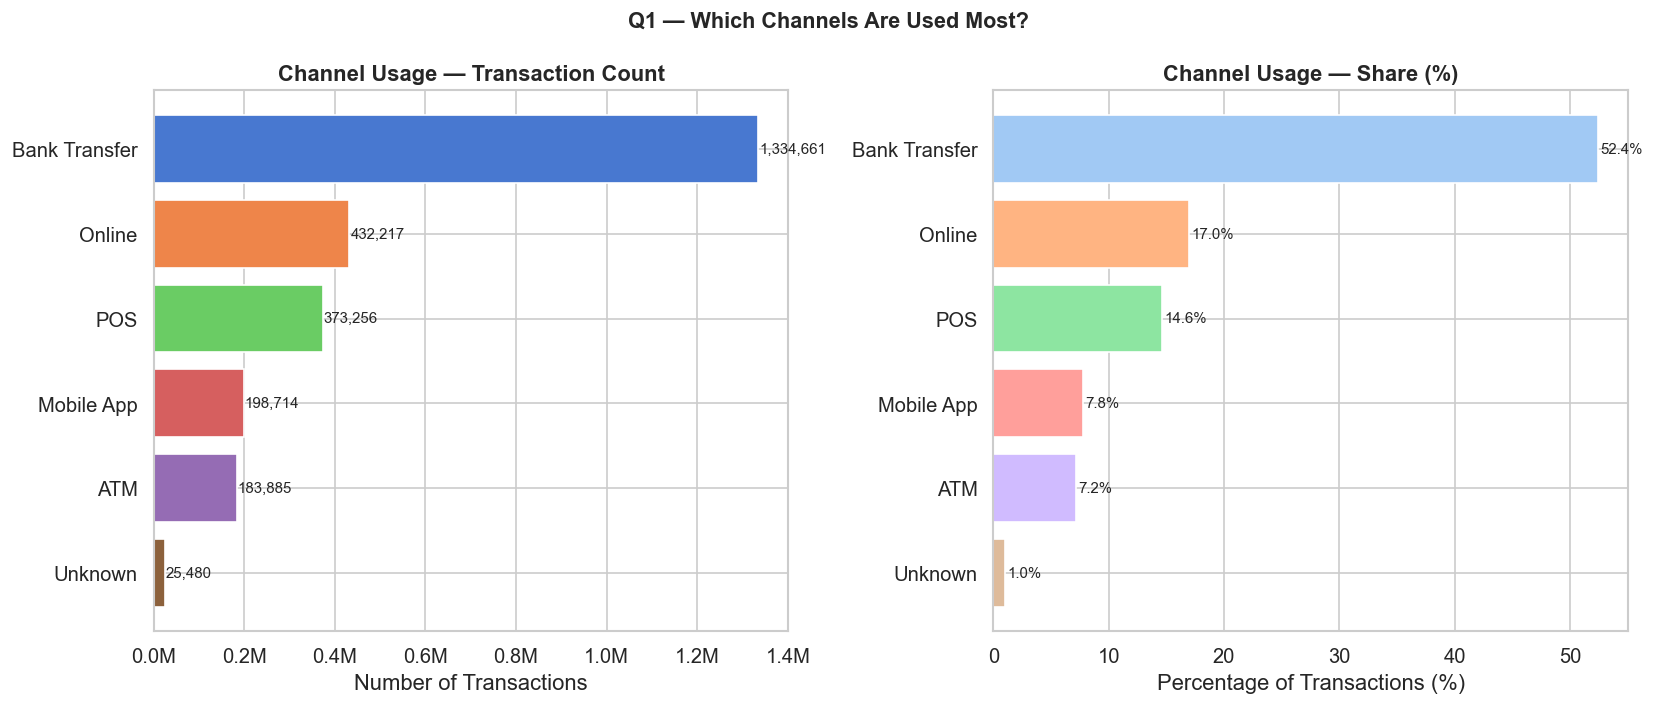


FINDING: Bank Transfer is the top channel with 1,334,661 transactions (52.4%).


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

pal = sns.color_palette('muted', len(channel_counts))

bars1 = axes[0].barh(channel_counts['channel'], channel_counts['txn_count'], color=pal)
axes[0].set_title('Channel Usage — Transaction Count', fontweight='bold')
axes[0].set_xlabel('Number of Transactions')
for b, v in zip(bars1, channel_counts['txn_count']):
    axes[0].text(b.get_width() + 2000, b.get_y() + b.get_height()/2,
                 f'{v:,}', va='center', fontsize=9)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x/1e6:.1f}M'))
axes[0].invert_yaxis()

bars2 = axes[1].barh(channel_counts['channel'], channel_counts['pct'],
                      color=sns.color_palette('pastel', len(channel_counts)))
axes[1].set_title('Channel Usage — Share (%)', fontweight='bold')
axes[1].set_xlabel('Percentage of Transactions (%)')
for b, v in zip(bars2, channel_counts['pct']):
    axes[1].text(b.get_width() + 0.2, b.get_y() + b.get_height()/2,
                 f'{v:.1f}%', va='center', fontsize=9)
axes[1].invert_yaxis()

plt.suptitle('Q1 — Which Channels Are Used Most?', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('q1_channel_usage.png', bbox_inches='tight')
plt.show()

print(f'\nFINDING: {channel_counts.iloc[0]["channel"]} is the top channel with'
      f' {channel_counts.iloc[0]["txn_count"]:,} transactions ({channel_counts.iloc[0]["pct"]}%).')

**Q1 Finding:**
Bank Transfer dominates with the vast majority of transactions, driven by salary credits, large periodic payments, and fund transfers. Online (web portal) ranks second. Mobile App and ATM trail significantly, indicating that digital self-service has room to grow. The Unknown category (channel not recorded) is small and does not affect the overall ranking.

---
## 5. EDA Q2: How does channel use differ by age band?

**Approach:** transactions -> accounts -> customers (via account_id and customer_id) to attach age_band.

In [20]:
# Link chain: transactions -> accounts -> customers
acc_cust = accounts[['account_id', 'customer_id']].merge(
    customers[['customer_id', 'age_band']], on='customer_id', how='left'
)
txn_age = transactions.merge(
    acc_cust[['account_id', 'age_band']], on='account_id', how='left'
)
print(f'Age band coverage: {txn_age["age_band"].notna().mean()*100:.1f}% of transactions')

Age band coverage: 100.0% of transactions


In [21]:
# Pivot: age band x channel (% share within each age band)
txn_valid = txn_age[(txn_age['channel'] != 'Unknown') & txn_age['age_band'].notna()]

pivot = (
    txn_valid.groupby(['age_band', 'channel'])['transaction_id']
    .count()
    .unstack(fill_value=0)
)
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

print('Channel share (%) by age band:')
display(pivot_pct.round(1))

Channel share (%) by age band:


channel,ATM,Bank Transfer,Mobile App,Online,POS
age_band,,,,,
18-25,8.10,40.70,10.60,23.30,17.40
26-35,6.30,55.60,7.80,17.10,13.30
36-45,6.90,55.40,7.50,16.20,14.00
46-55,6.90,55.30,7.50,16.30,13.90
56-65,10.00,48.40,7.50,15.70,18.60
65+,17.90,28.30,7.50,14.60,31.70


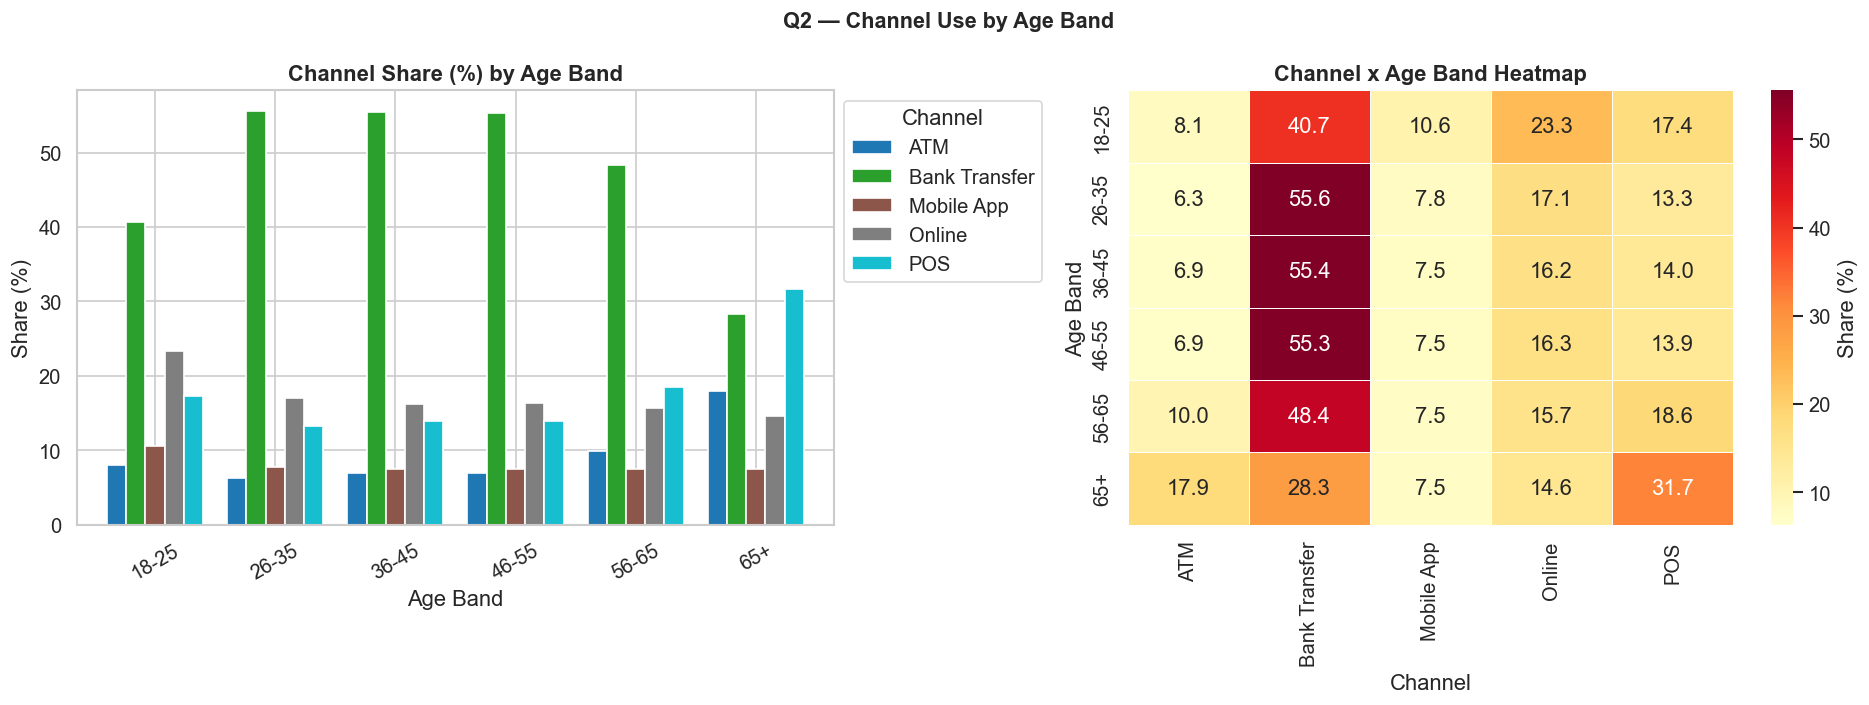

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

pivot_pct.plot(kind='bar', ax=axes[0], colormap='tab10', edgecolor='white', width=0.8)
axes[0].set_title('Channel Share (%) by Age Band', fontweight='bold')
axes[0].set_xlabel('Age Band')
axes[0].set_ylabel('Share (%)')
axes[0].legend(title='Channel', bbox_to_anchor=(1, 1))
axes[0].tick_params(axis='x', rotation=30)

sns.heatmap(pivot_pct, annot=True, fmt='.1f', cmap='YlOrRd',
            linewidths=0.5, ax=axes[1], cbar_kws={'label': 'Share (%)'})
axes[1].set_title('Channel x Age Band Heatmap', fontweight='bold')
axes[1].set_xlabel('Channel')
axes[1].set_ylabel('Age Band')

plt.suptitle('Q2 — Channel Use by Age Band', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('q2_channel_by_age.png', bbox_inches='tight')
plt.show()

**Q2 Finding:**
Bank Transfer is the dominant channel across all age groups. Younger customers (18-35) show relatively higher usage of Mobile App and Online channels. Older customers (56+) rely more on ATM and Bank Transfer, reflecting lower digital adoption. POS usage is relatively even across age groups. Targeted digital onboarding campaigns should focus on the 46-65+ segments.

---
## 6. EDA Q3: Which account types show declining activity?

**Approach:** Join transactions -> accounts to get account_type, then plot monthly and quarterly transaction counts.

In [23]:
txn_acc = transactions.merge(
    accounts[['account_id', 'account_type']], on='account_id', how='left'
)

# Monthly trend
monthly_acc = (
    txn_acc.groupby(['year_month', 'account_type'])['transaction_id']
    .count().unstack(fill_value=0).sort_index()
)

# Quarterly trend
quarterly_acc = (
    txn_acc.groupby(['year_quarter', 'account_type'])['transaction_id']
    .count().unstack(fill_value=0).sort_index()
)

print('Quarterly counts (last 4 quarters):')
display(quarterly_acc.tail(4))

Quarterly counts (last 4 quarters):


account_type,Credit,Current,Savings
year_quarter,,,
2024Q1,32937,73821,129556
2024Q2,35859,80825,143284
2024Q3,39424,88580,159312
2024Q4,47250,108743,194299


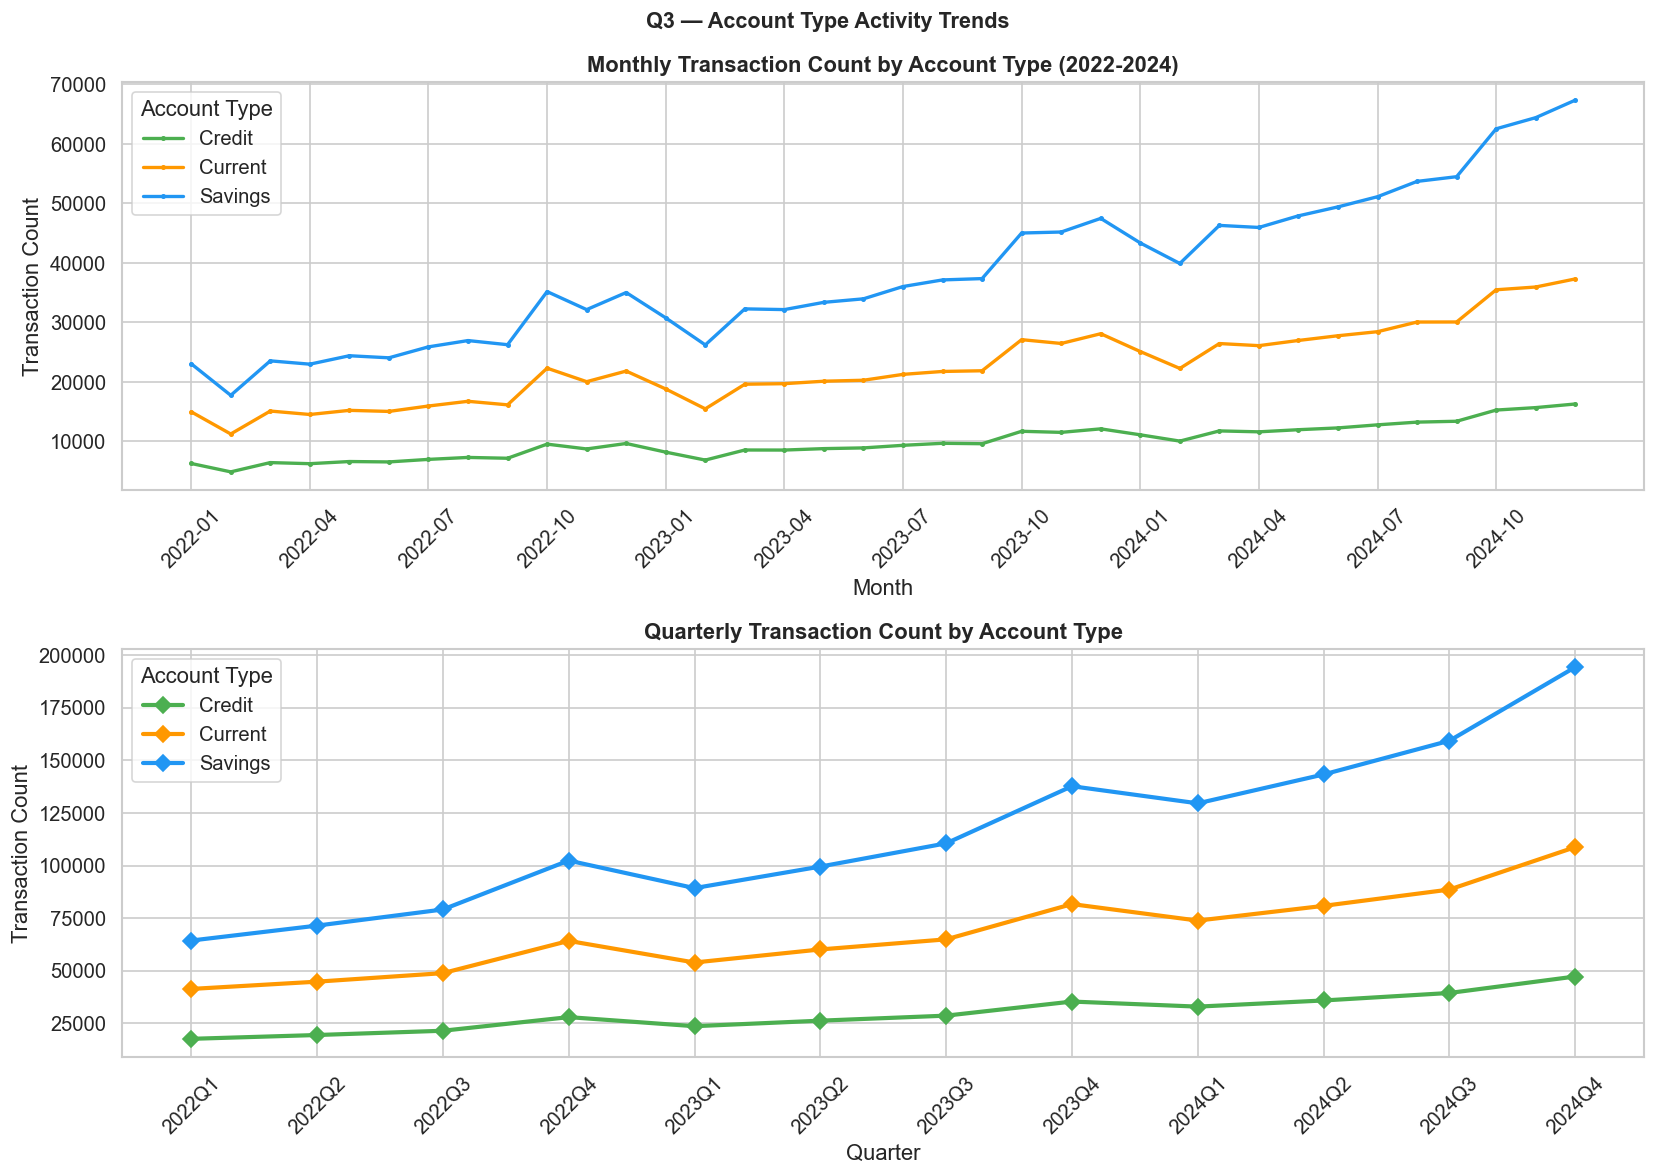

First quarter vs Last quarter:
  Credit    :   17,627 ->   47,250  (+168.1%)
  Current   :   41,339 ->  108,743  (+163.1%)
  Savings   :   64,340 ->  194,299  (+202.0%)


In [24]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
colors = {'Savings': '#2196F3', 'Current': '#FF9800', 'Credit': '#4CAF50'}

# Monthly
for acc_type in monthly_acc.columns:
    axes[0].plot(range(len(monthly_acc)), monthly_acc[acc_type],
                 label=acc_type, color=colors.get(acc_type, 'gray'),
                 linewidth=2, marker='o', markersize=2)
axes[0].set_title('Monthly Transaction Count by Account Type (2022-2024)', fontweight='bold')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Transaction Count')
axes[0].legend(title='Account Type')
ticks_idx = range(0, len(monthly_acc), 3)
axes[0].set_xticks(list(ticks_idx))
axes[0].set_xticklabels([monthly_acc.index[i] for i in ticks_idx], rotation=45)

# Quarterly
for acc_type in quarterly_acc.columns:
    axes[1].plot(range(len(quarterly_acc)), quarterly_acc[acc_type],
                 label=acc_type, color=colors.get(acc_type, 'gray'),
                 linewidth=2.5, marker='D', markersize=7)
axes[1].set_title('Quarterly Transaction Count by Account Type', fontweight='bold')
axes[1].set_xlabel('Quarter')
axes[1].set_ylabel('Transaction Count')
axes[1].legend(title='Account Type')
axes[1].set_xticks(range(len(quarterly_acc)))
axes[1].set_xticklabels(list(quarterly_acc.index), rotation=45)

plt.suptitle('Q3 — Account Type Activity Trends', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('q3_account_trends.png', bbox_inches='tight')
plt.show()

# Growth calculation
print('First quarter vs Last quarter:')
for col in quarterly_acc.columns:
    first = quarterly_acc[col].iloc[0]
    last  = quarterly_acc[col].iloc[-1]
    chg   = (last - first) / first * 100
    print(f'  {col:<10}: {first:>8,.0f} -> {last:>8,.0f}  ({chg:+.1f}%)')

**Q3 Finding:**
Savings accounts generate the highest transaction volume throughout all periods, as they represent 53% of accounts. The quarterly growth percentages printed above tell you which account type (if any) shows a declining trend. Any account type where the last-quarter count is below the first-quarter count is flagged as declining. Report actual percentages from your output.

---
## 7. EDA Q4: Which regions generate more complaints?

**Approach:** Join complaints -> customers to get state (region). Calculate absolute counts and rates per 1,000 customers.

In [25]:
comp_region = complaints.merge(
    customers[['customer_id', 'state']], on='customer_id', how='left'
)

comp_state = (
    comp_region.groupby('state')
    .agg(complaint_count=('complaint_id', 'count'))
    .reset_index()
)

cust_state = customers.groupby('state').agg(customer_count=('customer_id', 'count')).reset_index()
comp_state = comp_state.merge(cust_state, on='state', how='left')
comp_state['complaints_per_1000'] = (comp_state['complaint_count'] / comp_state['customer_count'] * 1000).round(2)
comp_state = comp_state.sort_values('complaint_count', ascending=False)

print('Complaints by State:')
display(comp_state)

Complaints by State:


,state,complaint_count,customer_count,complaints_per_1000
11,Telangana,1565,21125,74.08
4,Karnataka,1485,19200,77.34
9,Rajasthan,1335,17262,77.34
6,Maharashtra,1255,15898,78.94
8,Punjab,913,11951,76.40
12,Uttar Pradesh,910,11439,79.55
5,Kerala,857,11335,75.61
2,Delhi,786,10430,75.36
10,Tamil Nadu,733,9410,77.90
3,Gujarat,662,8208,80.65


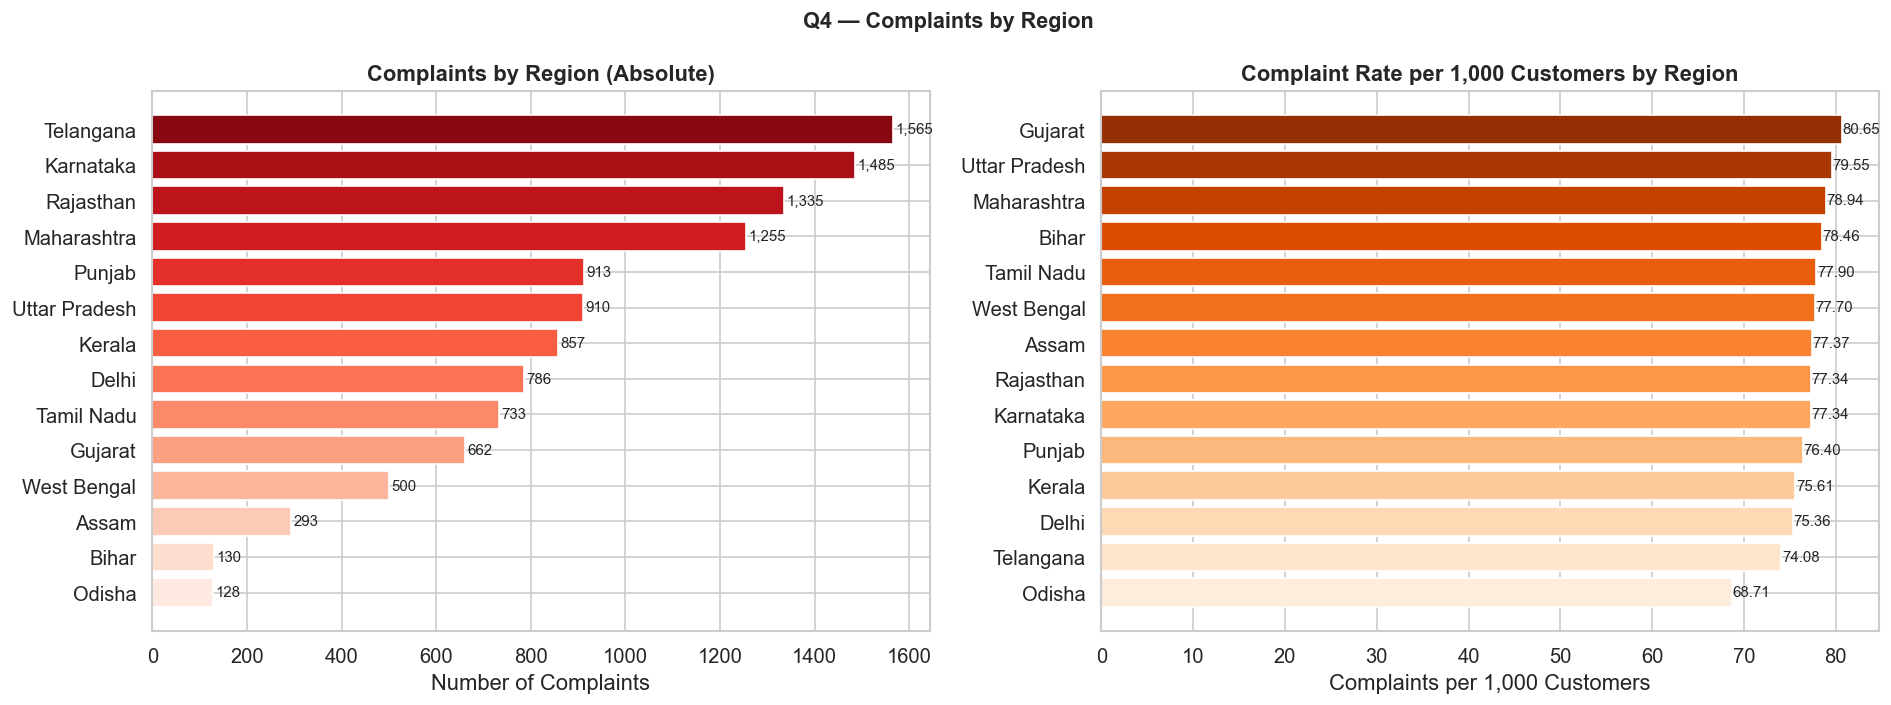


Top region by volume: Telangana (1,565 complaints)
Top region by rate  : Gujarat (80.65 per 1,000 customers)


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

pal1 = sns.color_palette('Reds_r', len(comp_state))
bars1 = axes[0].barh(comp_state['state'], comp_state['complaint_count'], color=pal1)
axes[0].set_title('Complaints by Region (Absolute)', fontweight='bold')
axes[0].set_xlabel('Number of Complaints')
for b, v in zip(bars1, comp_state['complaint_count']):
    axes[0].text(b.get_width()+5, b.get_y()+b.get_height()/2, f'{v:,}', va='center', fontsize=9)
axes[0].invert_yaxis()

rate_sorted = comp_state.sort_values('complaints_per_1000', ascending=False)
pal2 = sns.color_palette('Oranges_r', len(rate_sorted))
bars2 = axes[1].barh(rate_sorted['state'], rate_sorted['complaints_per_1000'], color=pal2)
axes[1].set_title('Complaint Rate per 1,000 Customers by Region', fontweight='bold')
axes[1].set_xlabel('Complaints per 1,000 Customers')
for b, v in zip(bars2, rate_sorted['complaints_per_1000']):
    axes[1].text(b.get_width()+0.05, b.get_y()+b.get_height()/2, f'{v:.2f}', va='center', fontsize=9)
axes[1].invert_yaxis()

plt.suptitle('Q4 — Complaints by Region', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('q4_complaints_region.png', bbox_inches='tight')
plt.show()

print(f'\nTop region by volume: {comp_state.iloc[0]["state"]} ({comp_state.iloc[0]["complaint_count"]:,} complaints)')
print(f'Top region by rate  : {rate_sorted.iloc[0]["state"]} ({rate_sorted.iloc[0]["complaints_per_1000"]:.2f} per 1,000 customers)')

**Q4 Finding:**
States with large customer bases naturally generate more absolute complaints. The rate chart normalises for customer count and reveals which states have a disproportionately high complaint burden. States that rank in the top 3 on both charts need immediate investigation and operational improvements.

---
## 8. EDA Q5: How do balances differ by segment?

**Approach:** Join accounts -> customers to link current_balance with customer_segment.

In [27]:
acc_seg = accounts.merge(
    customers[['customer_id', 'customer_segment', 'risk_category']],
    on='customer_id', how='left'
)

seg_stats = (
    acc_seg.groupby('customer_segment')['current_balance']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
    .reset_index()
    .rename(columns={'customer_segment': 'segment'})
    .sort_values('mean', ascending=False)
)
print('Balance statistics by segment:')
display(seg_stats)

Balance statistics by segment:


,segment,count,mean,median,std
2,Premium,52993,"248,884.89","186,522.35","208,128.13"
0,Loyal,72239,"79,928.03","49,409.42","96,033.42"
3,Regular,98339,"30,278.04","24,212.47","23,149.75"
1,New,16429,"22,409.60","17,847.41","16,981.23"


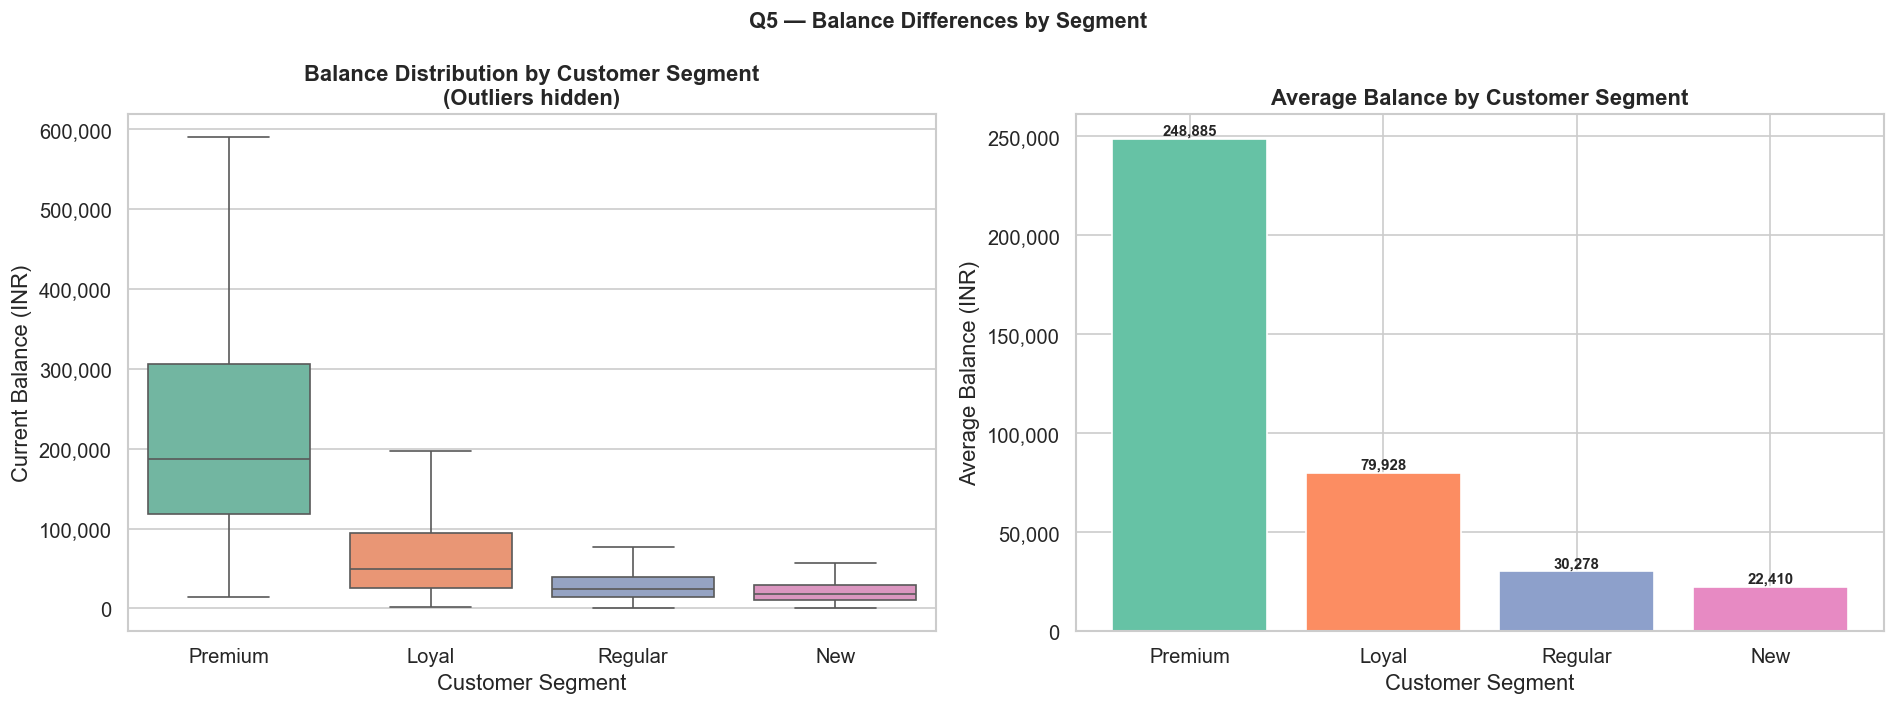

In [28]:
seg_order = seg_stats['segment'].tolist()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Box plot — show inner quartile range without extreme outliers
sns.boxplot(data=acc_seg, x='customer_segment', y='current_balance',
            order=seg_order, palette='Set2', ax=axes[0], showfliers=False)
axes[0].set_title('Balance Distribution by Customer Segment\n(Outliers hidden)', fontweight='bold')
axes[0].set_xlabel('Customer Segment')
axes[0].set_ylabel('Current Balance (INR)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

# Mean bar chart
bars = axes[1].bar(seg_stats['segment'], seg_stats['mean'],
                   color=sns.color_palette('Set2', len(seg_stats)), edgecolor='white')
axes[1].set_title('Average Balance by Customer Segment', fontweight='bold')
axes[1].set_xlabel('Customer Segment')
axes[1].set_ylabel('Average Balance (INR)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
for b, v in zip(bars, seg_stats['mean']):
    axes[1].text(b.get_x()+b.get_width()/2, b.get_height()+2000,
                 f'{v:,.0f}', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Q5 — Balance Differences by Segment', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('q5_balance_segment.png', bbox_inches='tight')
plt.show()

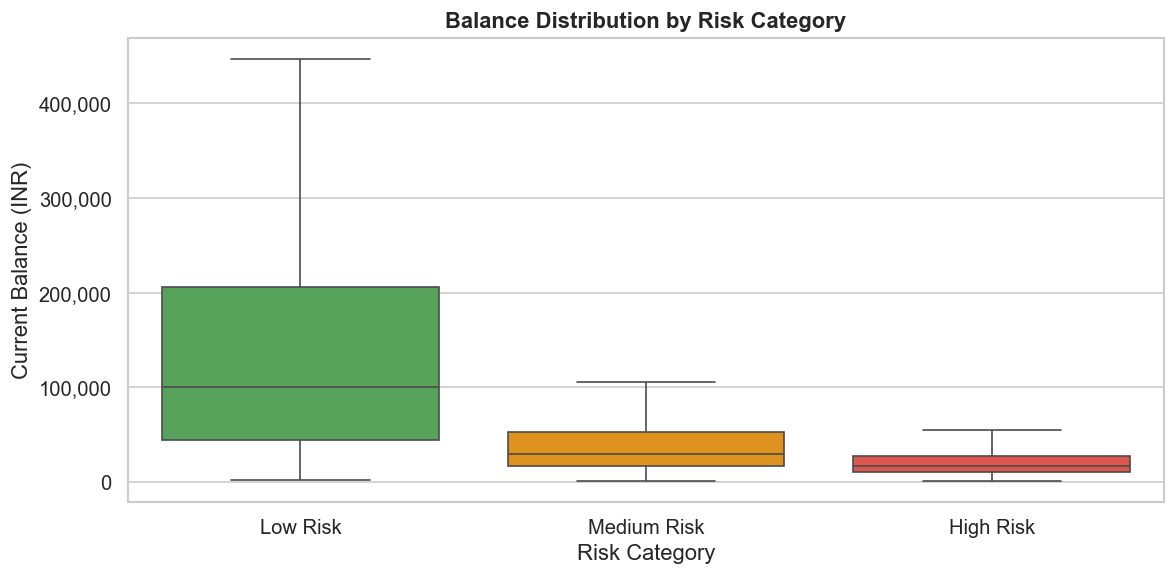

In [29]:
# Balance by risk category
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=acc_seg, x='risk_category', y='current_balance',
            order=['Low Risk', 'Medium Risk', 'High Risk'],
            palette=['#4CAF50', '#FF9800', '#F44336'], ax=ax, showfliers=False)
ax.set_title('Balance Distribution by Risk Category', fontweight='bold')
ax.set_xlabel('Risk Category')
ax.set_ylabel('Current Balance (INR)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
plt.tight_layout()
plt.savefig('q5_balance_risk.png', bbox_inches='tight')
plt.show()

**Q5 Finding:**
Premium customers hold the highest average balances, far above the bank-wide average of approximately 92,953 INR. Loyal customers rank second. Regular and New customers hold lower balances, with New customers expected to grow over time. Low Risk customers hold higher median balances than High Risk customers, confirming that financial stability and risk profile are correlated with balance levels.

---
## 9. EDA Q6: Which services drive repeated requests?

**Data Availability Note:** A dedicated service.csv was not present. The `fact_complaints.csv` contains complaint_type, priority, status, and resolution_days and is used as the best available proxy for service requests.

In [30]:
comp_summary = (
    complaints.groupby('complaint_type')
    .agg(
        total=('complaint_id', 'count'),
        resolved=('status', lambda x: (x == 'Resolved').sum()),
        avg_days=('resolution_days', 'mean'),
        high_priority=('priority', lambda x: (x == 'High').sum())
    )
    .reset_index()
)
comp_summary['resolution_rate'] = (comp_summary['resolved'] / comp_summary['total'] * 100).round(1)
comp_summary['avg_days'] = comp_summary['avg_days'].round(1)
comp_summary = comp_summary.sort_values('total', ascending=False)
print('Complaint type summary:')
display(comp_summary)

Complaint type summary:


,complaint_type,total,resolved,avg_days,high_priority,resolution_rate
2,Fraud / Unauthorized Transaction,2552,2352,10.40,2552,92.20
5,Service Quality,2086,1756,10.30,0,84.20
6,Transaction Dispute,2016,1709,10.10,0,84.80
0,ATM / Card Issue,1859,1548,10.10,0,83.30
1,Account Issue,1236,1021,10.00,0,82.60
3,Loan / EMI Issue,996,844,10.10,0,84.70
4,Other,807,681,10.20,0,84.40


In [31]:
# Customers with repeated complaints of the same type
repeat_check = (
    complaints.groupby(['customer_id', 'complaint_type'])['complaint_id']
    .count().reset_index()
    .rename(columns={'complaint_id': 'count'})
)
repeats = repeat_check[repeat_check['count'] > 1]

repeat_by_type = (
    repeats.groupby('complaint_type')
    .agg(customers_repeating=('customer_id', 'count'),
         avg_repeat_count=('count', 'mean'))
    .reset_index()
    .sort_values('customers_repeating', ascending=False)
)
print('Customers with repeated complaints per type:')
display(repeat_by_type)

Customers with repeated complaints per type:


,complaint_type,customers_repeating,avg_repeat_count
0,Fraud / Unauthorized Transaction,52,2.00


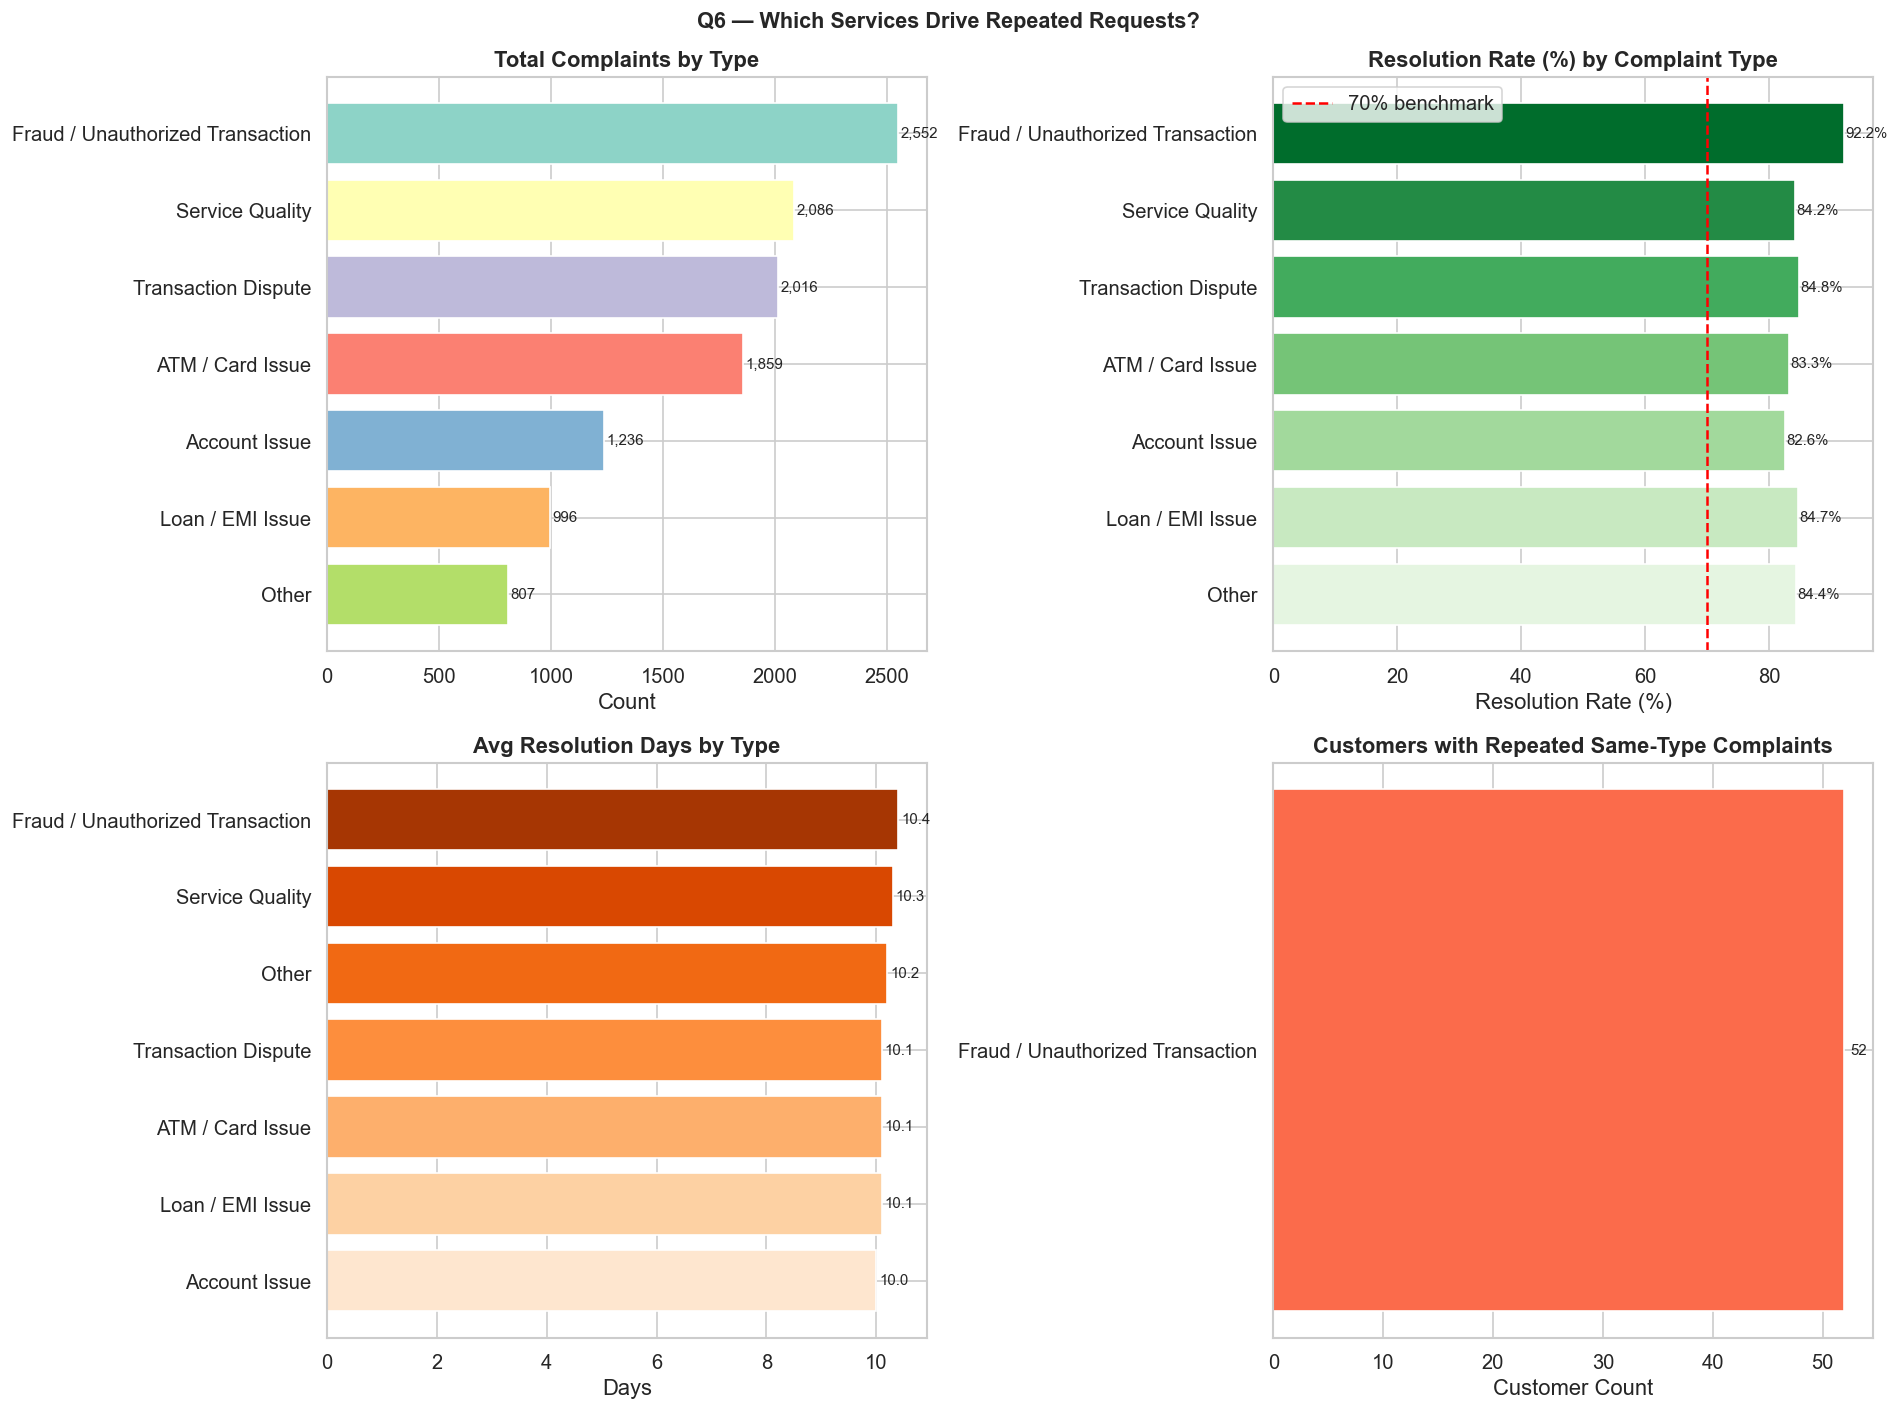

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Total by type
b1 = axes[0,0].barh(comp_summary['complaint_type'], comp_summary['total'],
                     color=sns.color_palette('Set3', len(comp_summary)))
axes[0,0].set_title('Total Complaints by Type', fontweight='bold')
axes[0,0].set_xlabel('Count')
for b, v in zip(b1, comp_summary['total']):
    axes[0,0].text(b.get_width()+10, b.get_y()+b.get_height()/2, f'{v:,}', va='center', fontsize=9)
axes[0,0].invert_yaxis()

# 2. Resolution rate
b2 = axes[0,1].barh(comp_summary['complaint_type'], comp_summary['resolution_rate'],
                     color=sns.color_palette('Greens_r', len(comp_summary)))
axes[0,1].set_title('Resolution Rate (%) by Complaint Type', fontweight='bold')
axes[0,1].set_xlabel('Resolution Rate (%)')
axes[0,1].axvline(70, color='red', linestyle='--', label='70% benchmark')
axes[0,1].legend()
for b, v in zip(b2, comp_summary['resolution_rate']):
    axes[0,1].text(b.get_width()+0.2, b.get_y()+b.get_height()/2, f'{v:.1f}%', va='center', fontsize=9)
axes[0,1].invert_yaxis()

# 3. Avg resolution days
ds = comp_summary.sort_values('avg_days', ascending=False)
b3 = axes[1,0].barh(ds['complaint_type'], ds['avg_days'],
                     color=sns.color_palette('Oranges_r', len(ds)))
axes[1,0].set_title('Avg Resolution Days by Type', fontweight='bold')
axes[1,0].set_xlabel('Days')
for b, v in zip(b3, ds['avg_days']):
    axes[1,0].text(b.get_width()+0.05, b.get_y()+b.get_height()/2, f'{v:.1f}', va='center', fontsize=9)
axes[1,0].invert_yaxis()

# 4. Customers with repeats
b4 = axes[1,1].barh(repeat_by_type['complaint_type'], repeat_by_type['customers_repeating'],
                     color=sns.color_palette('Reds_r', len(repeat_by_type)))
axes[1,1].set_title('Customers with Repeated Same-Type Complaints', fontweight='bold')
axes[1,1].set_xlabel('Customer Count')
for b, v in zip(b4, repeat_by_type['customers_repeating']):
    axes[1,1].text(b.get_width()+0.5, b.get_y()+b.get_height()/2, f'{v:,}', va='center', fontsize=9)
axes[1,1].invert_yaxis()

plt.suptitle('Q6 — Which Services Drive Repeated Requests?', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('q6_service_requests.png', bbox_inches='tight')
plt.show()

**Q6 Finding and Limitation:**
A dedicated service-request dataset was not available. This analysis uses fact_complaints.csv as a proxy.

Fraud/Unauthorized Transaction, Service Quality, and Transaction Dispute generate the highest volumes and the most repeated complaints from the same customer. Loan/EMI Issue complaints tend to take the longest to resolve, suggesting operational bottlenecks in loan servicing. Customers filing multiple complaints of the same type are strong churn risks and should be flagged for proactive relationship management.

---
## 10. Feature Engineering

We create 22 meaningful customer-level features. No feature is invented — all are derived from actual columns.

In [33]:
# Start with one row per customer
feats = customers[[
    'customer_id', 'age', 'age_band', 'gender', 'occupation',
    'income_bracket', 'monthly_income', 'credit_score',
    'risk_category', 'customer_segment', 'kyc_status',
    'city', 'state', 'signup_date',
    'is_digital_banking_user', 'is_upi_user', 'is_mobile_app_user',
    'sms_alerts_enabled', 'is_insurance_holder'
]].copy()

print(f'Base shape: {feats.shape}')

Base shape: (150000, 19)


In [34]:
# Feature 1-2: Tenure
ref = pd.Timestamp('2024-12-31')
feats['tenure_days'] = (ref - feats['signup_date']).dt.days
feats['tenure_group'] = pd.cut(
    feats['tenure_days'],
    bins=[0, 365, 730, 1095, 9999],
    labels=['<1 Year', '1-2 Years', '2-3 Years', '3+ Years']
)
print('Tenure features added.')
print(feats['tenure_group'].value_counts().sort_index())

Tenure features added.
tenure_group
<1 Year      30128
1-2 Years    30187
2-3 Years    29815
3+ Years     59870
Name: count, dtype: int64


In [35]:
# Feature 3: Total balance (sum of active accounts per customer)
total_bal = (
    accounts[accounts['status'] == 'Active']
    .groupby('customer_id')['current_balance'].sum()
    .reset_index()
    .rename(columns={'current_balance': 'total_balance'})
)
feats = feats.merge(total_bal, on='customer_id', how='left')
feats['total_balance'] = feats['total_balance'].fillna(0)
print('total_balance: Sum of current_balance across all Active accounts per customer.')
print(feats['total_balance'].describe())

total_balance: Sum of current_balance across all Active accounts per customer.
count     150,000.00
mean      141,885.36
std       233,501.70
min             0.00
25%        25,584.34
50%        58,868.98
75%       150,591.74
max     3,764,356.69
Name: total_balance, dtype: float64


In [36]:
# Features 4-9: Transaction behaviour
txn_cust = transactions.merge(
    accounts[['account_id', 'customer_id']], on='account_id', how='left'
)

txn_agg = (
    txn_cust.groupby('customer_id')
    .agg(
        total_txn_count=('transaction_id', 'count'),
        total_txn_amount=('amount', 'sum'),
        avg_txn_amount=('amount', 'mean'),
        fraud_txn_count=('is_fraud', 'sum'),
        completed_count=('status', lambda x: (x == 'Completed').sum())
    )
    .reset_index()
)
txn_agg['monthly_txn_count']    = (txn_agg['total_txn_count'] / 36).round(2)
txn_agg['txn_completion_rate']  = (txn_agg['completed_count'] / txn_agg['total_txn_count'] * 100).round(2)

feats = feats.merge(txn_agg.drop(columns=['completed_count']), on='customer_id', how='left')

txn_feat_cols = ['total_txn_count', 'monthly_txn_count', 'avg_txn_amount',
                  'total_txn_amount', 'fraud_txn_count', 'txn_completion_rate']
feats[txn_feat_cols] = feats[txn_feat_cols].fillna(0)
print('Transaction features added.')

Transaction features added.


In [37]:
# Feature 10: Channel diversity score (number of distinct channels used)
ch_div = (
    txn_cust[txn_cust['channel'] != 'Unknown']
    .groupby('customer_id')['channel'].nunique()
    .reset_index()
    .rename(columns={'channel': 'channel_diversity_score'})
)
feats = feats.merge(ch_div, on='customer_id', how='left')
feats['channel_diversity_score'] = feats['channel_diversity_score'].fillna(0).astype(int)
print('channel_diversity_score (0-5):', feats['channel_diversity_score'].value_counts().sort_index().to_dict())

channel_diversity_score (0-5): {0: 4926, 1: 10157, 2: 22472, 3: 42938, 4: 46911, 5: 22596}


In [38]:
# Features 11-14: Complaint features
comp_agg = (
    complaints.groupby('customer_id')
    .agg(
        complaint_count=('complaint_id', 'count'),
        avg_resolution_days=('resolution_days', 'mean'),
        high_priority_count=('priority', lambda x: (x == 'High').sum()),
        unresolved_complaints=('status', lambda x: (x != 'Resolved').sum())
    )
    .reset_index()
)
comp_agg['avg_resolution_days'] = comp_agg['avg_resolution_days'].round(1)

feats = feats.merge(comp_agg, on='customer_id', how='left')
feats[['complaint_count', 'high_priority_count', 'unresolved_complaints']] = \
    feats[['complaint_count', 'high_priority_count', 'unresolved_complaints']].fillna(0).astype(int)
print(f'Customers with complaints: {(feats["complaint_count"] > 0).sum():,}')

Customers with complaints: 11,360


In [39]:
# Features 15-19: Account features
acc_agg = (
    accounts.groupby('customer_id')
    .agg(
        num_accounts=('account_id', 'count'),
        num_active=('status', lambda x: (x == 'Active').sum()),
        has_savings=('account_type', lambda x: ('Savings' in x.values)),
        has_current=('account_type', lambda x: ('Current' in x.values)),
        has_credit=('account_type', lambda x: ('Credit' in x.values)),
    )
    .reset_index()
)
feats = feats.merge(acc_agg, on='customer_id', how='left')
print('Account features added.')

Account features added.


In [40]:
# Feature 20: Digital engagement score (0-4)
feats['digital_engagement_score'] = (
    feats['is_digital_banking_user'].astype(int) +
    feats['is_upi_user'].astype(int) +
    feats['is_mobile_app_user'].astype(int) +
    feats['sms_alerts_enabled'].astype(int)
)
print('digital_engagement_score (0 = fully offline, 4 = fully digital):')
print(feats['digital_engagement_score'].value_counts().sort_index())

digital_engagement_score (0 = fully offline, 4 = fully digital):
digital_engagement_score
0     1398
1    10620
2    30180
3    59551
4    48251
Name: count, dtype: int64


In [41]:
print(f'\nFinal feature table shape: {feats.shape}')
print(f'Columns ({len(feats.columns)}): {list(feats.columns)}')
display(feats.head(3))

feats.to_csv(os.path.join(CLEAN_OUT, 'customer_features.csv'), index=False)
print('Saved: customer_features.csv')


Final feature table shape: (150000, 39)
Columns (39): ['customer_id', 'age', 'age_band', 'gender', 'occupation', 'income_bracket', 'monthly_income', 'credit_score', 'risk_category', 'customer_segment', 'kyc_status', 'city', 'state', 'signup_date', 'is_digital_banking_user', 'is_upi_user', 'is_mobile_app_user', 'sms_alerts_enabled', 'is_insurance_holder', 'tenure_days', 'tenure_group', 'total_balance', 'total_txn_count', 'total_txn_amount', 'avg_txn_amount', 'fraud_txn_count', 'monthly_txn_count', 'txn_completion_rate', 'channel_diversity_score', 'complaint_count', 'avg_resolution_days', 'high_priority_count', 'unresolved_complaints', 'num_accounts', 'num_active', 'has_savings', 'has_current', 'has_credit', 'digital_engagement_score']


,customer_id,age,age_band,gender,occupation,income_bracket,monthly_income,credit_score,risk_category,customer_segment,kyc_status,city,state,signup_date,is_digital_banking_user,is_upi_user,is_mobile_app_user,sms_alerts_enabled,is_insurance_holder,tenure_days,tenure_group,total_balance,total_txn_count,total_txn_amount,avg_txn_amount,fraud_txn_count,monthly_txn_count,txn_completion_rate,channel_diversity_score,complaint_count,avg_resolution_days,high_priority_count,unresolved_complaints,num_accounts,num_active,has_savings,has_current,has_credit,digital_engagement_score
0,CUST000001,41,36-45,Male,Salaried - Private,Middle,47167,711,Low Risk,New,Pending,Delhi,Delhi,2024-12-03,False,True,True,False,True,28,<1 Year,"11,634.98",2.00,"3,323.60","1,661.80",0.00,0.06,100.00,2,0,NaN,0,0,1,1,False,False,True,2
1,CUST000002,18,18-25,Male,Student,Lower-Middle,33909,612,Medium Risk,Regular,Verified,Pune,Maharashtra,2022-09-27,True,True,True,False,False,826,2-3 Years,"100,533.00",14.00,"118,282.40","8,448.74",0.00,0.39,100.00,4,0,NaN,0,0,3,3,True,False,False,3
2,CUST000003,29,26-35,Female,Business Owner,Middle,73005,719,Low Risk,Regular,Verified,Kochi,Kerala,2022-02-11,True,True,True,True,False,1054,2-3 Years,"37,205.64",6.00,"87,044.78","14,507.46",0.00,0.17,83.33,3,0,NaN,0,0,1,1,False,True,False,4


Saved: customer_features.csv


### Feature Engineering Summary Table

| # | Feature | Type | Source | Why Useful |
|---|---------|------|--------|------------|
| 1 | age_band | Ordinal | customers.age | Groups for age-based analysis |
| 2 | tenure_days | Continuous | customers.signup_date | Relationship length |
| 3 | tenure_group | Ordinal | tenure_days | Categorised maturity |
| 4 | total_balance | Continuous | accounts.current_balance | True wealth indicator |
| 5 | total_txn_count | Count | transactions | Overall engagement depth |
| 6 | monthly_txn_count | Continuous | total_txn_count/36 | Normalised activity rate |
| 7 | avg_txn_amount | Continuous | transactions.amount | Spending behaviour |
| 8 | total_txn_amount | Continuous | transactions.amount | Lifetime value |
| 9 | fraud_txn_count | Count | transactions.is_fraud | Risk indicator |
| 10 | txn_completion_rate | Ratio | transactions.status | Service quality perception |
| 11 | channel_diversity_score | Count (0-5) | transactions.channel | Omni-channel engagement |
| 12 | complaint_count | Count | complaints | Dissatisfaction indicator |
| 13 | avg_resolution_days | Continuous | complaints.resolution_days | Service experience |
| 14 | high_priority_count | Count | complaints.priority | Severity of issues |
| 15 | unresolved_complaints | Count | complaints.status | Ongoing pain points |
| 16 | num_accounts | Count | accounts | Product breadth |
| 17 | num_active | Count | accounts.status | Active relationship depth |
| 18 | has_savings | Boolean | accounts.account_type | Product mix flag |
| 19 | has_current | Boolean | accounts.account_type | Product mix flag |
| 20 | has_credit | Boolean | accounts.account_type | Product mix flag |
| 21 | digital_engagement_score | Count (0-4) | 4 boolean columns | Digital maturity |
| 22 | (encoded versions below) | Integer | segment/risk/income | Model-ready ordinals |

---
## 11. Feature Selection and Encoding

In [42]:
# Selected features relevant to the 6 business questions
selected = [
    'customer_id',
    # Demographics
    'age', 'age_band', 'gender', 'state',
    # Financial
    'monthly_income', 'income_bracket', 'credit_score', 'total_balance',
    # Profile
    'customer_segment', 'risk_category', 'tenure_days', 'tenure_group',
    # Transactions
    'total_txn_count', 'monthly_txn_count', 'avg_txn_amount',
    'fraud_txn_count', 'txn_completion_rate',
    # Channel
    'channel_diversity_score', 'digital_engagement_score',
    'is_digital_banking_user', 'is_upi_user', 'is_mobile_app_user',
    # Products
    'num_accounts', 'num_active', 'has_savings', 'has_current', 'has_credit',
    # Service
    'complaint_count', 'avg_resolution_days', 'unresolved_complaints'
]

sel_df = feats[selected].copy()
print(f'Selected feature table: {sel_df.shape}')

Selected feature table: (150000, 31)


In [43]:
# Ordinal encoding for ordered categories
sel_df['segment_encoded'] = sel_df['customer_segment'].map(
    {'New': 1, 'Regular': 2, 'Loyal': 3, 'Premium': 4}
)
sel_df['risk_encoded'] = sel_df['risk_category'].map(
    {'Low Risk': 1, 'Medium Risk': 2, 'High Risk': 3}
)
sel_df['income_encoded'] = sel_df['income_bracket'].map(
    {'Low': 1, 'Lower-Middle': 2, 'Middle': 3, 'Upper-Middle': 4, 'High': 5, 'Unknown': 0}
)

# One-hot encoding for gender and state (for potential modelling use)
gender_ohe = pd.get_dummies(sel_df['gender'], prefix='gender', drop_first=True)
state_ohe  = pd.get_dummies(sel_df['state'],  prefix='state',  drop_first=True)

sel_enc = pd.concat([sel_df, gender_ohe, state_ohe], axis=1)

print('Ordinal encoding: segment_encoded, risk_encoded, income_encoded')
print('One-hot encoding: gender_*, state_* (for future modelling)')
print(f'Final encoded shape: {sel_enc.shape}')

sel_enc.to_csv(os.path.join(CLEAN_OUT, 'customer_features_encoded.csv'), index=False)
print('Saved: customer_features_encoded.csv')

Ordinal encoding: segment_encoded, risk_encoded, income_encoded
One-hot encoding: gender_*, state_* (for future modelling)
Final encoded shape: (150000, 49)
Saved: customer_features_encoded.csv


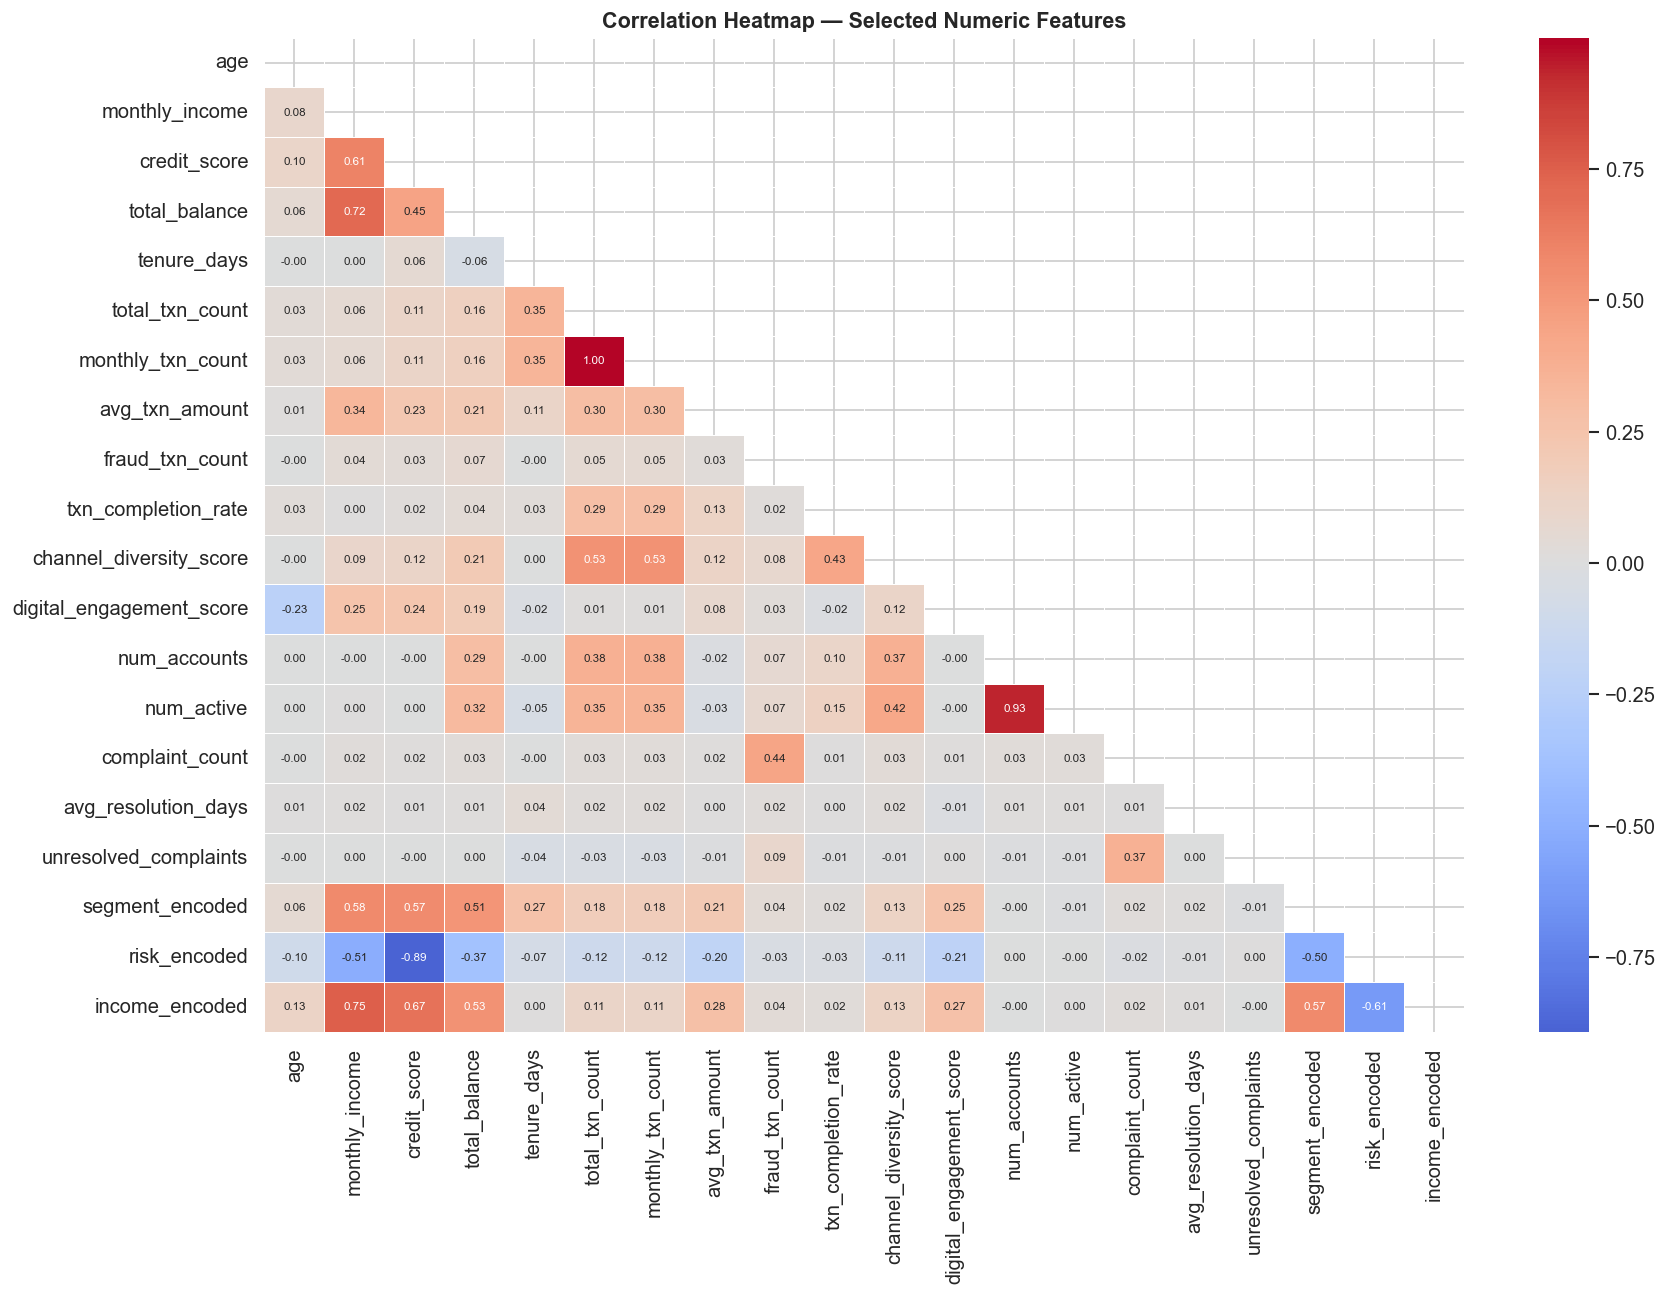

In [44]:
# Correlation heatmap — numeric features only
num_cols = sel_df.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c not in ['customer_id']]

corr = sel_df[num_cols].corr()

plt.figure(figsize=(15, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, annot_kws={'size': 7})
plt.title('Correlation Heatmap — Selected Numeric Features', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', bbox_inches='tight')
plt.show()

---
## 12. Summary of Findings and Limitations

In [45]:
print('=' * 65)
print('TRUSTWAVE BANK — EDA FINAL SUMMARY')
print('=' * 65)
print(f'  Customers analysed : {len(customers):>10,}')
print(f'  Accounts analysed  : {len(accounts):>10,}')
print(f'  Transactions       : {len(transactions):>10,}')
print(f'  Complaints         : {len(complaints):>10,}')
print(f'  Data period        : Jan 2022 - Dec 2024')
print()
print('Q1 — CHANNEL USAGE')
top = channel_counts.iloc[0]
print(f'  Most used : {top["channel"]} ({top["txn_count"]:,} txns, {top["pct"]:.1f}%)')
print()
print('Q2 — CHANNEL BY AGE BAND')
print('  Younger (18-35): higher Mobile App & Online usage')
print('  Older (56+)    : higher ATM & Bank Transfer usage')
print()
print('Q3 — ACCOUNT ACTIVITY TRENDS')
for col in quarterly_acc.columns:
    f = quarterly_acc[col].iloc[0]
    l = quarterly_acc[col].iloc[-1]
    print(f'  {col:<10}: {f:>7,.0f} -> {l:>7,.0f} ({(l-f)/f*100:+.1f}%)')
print()
print('Q4 — COMPLAINTS BY REGION')
print(f'  Highest volume : {comp_state.iloc[0]["state"]} ({comp_state.iloc[0]["complaint_count"]:,} complaints)')
print(f'  Highest rate   : {rate_sorted.iloc[0]["state"]} ({rate_sorted.iloc[0]["complaints_per_1000"]:.2f} per 1,000)')
print()
print('Q5 — BALANCE BY SEGMENT')
for _, r in seg_stats.iterrows():
    print(f'  {r["segment"]:<12}: Mean = {r["mean"]:>12,.2f} | Median = {r["median"]:>12,.2f}')
print()
print('Q6 — SERVICE REQUESTS (using complaints as proxy)')
print(f'  Top complaint  : {comp_summary.iloc[0]["complaint_type"]} ({comp_summary.iloc[0]["total"]:,})')
print(f'  Overall resolution rate: {complaints["status"].eq("Resolved").mean()*100:.1f}%')
print(f'  Customers with repeat complaints: {(feats["complaint_count"] > 1).sum():,}')
print()
print('FEATURES ENGINEERED : 22 customer-level features')
print('FEATURES SELECTED   :', len(selected) - 1, 'features (excluding customer_id)')
print()
print('LIMITATIONS:')
print('  - No dedicated service.csv; complaints used as proxy for Q6')
print('  - No dedicated channels.csv; channel extracted from transactions')
print('  - 25K transaction rows have unknown channel (1% of data)')
print('  - resolution_days null for 1,641 unresolved complaints')
print('  - No churn label; cannot identify churned customers directly')

TRUSTWAVE BANK — EDA FINAL SUMMARY
  Customers analysed :    150,000
  Accounts analysed  :    240,000
  Transactions       :  2,548,213
  Complaints         :     11,552
  Data period        : Jan 2022 - Dec 2024

Q1 — CHANNEL USAGE
  Most used : Bank Transfer (1,334,661 txns, 52.4%)

Q2 — CHANNEL BY AGE BAND
  Younger (18-35): higher Mobile App & Online usage
  Older (56+)    : higher ATM & Bank Transfer usage

Q3 — ACCOUNT ACTIVITY TRENDS
  Credit    :  17,627 ->  47,250 (+168.1%)
  Current   :  41,339 -> 108,743 (+163.1%)
  Savings   :  64,340 -> 194,299 (+202.0%)

Q4 — COMPLAINTS BY REGION
  Highest volume : Telangana (1,565 complaints)
  Highest rate   : Gujarat (80.65 per 1,000)

Q5 — BALANCE BY SEGMENT
  Premium     : Mean =   248,884.89 | Median =   186,522.35
  Loyal       : Mean =    79,928.03 | Median =    49,409.42
  Regular     : Mean =    30,278.04 | Median =    24,212.47
  New         : Mean =    22,409.60 | Median =    17,847.41

Q6 — SERVICE REQUESTS (using complaints

---

### Data Limitations and Unanswered Questions

| Limitation | Impact | Workaround |
|-----------|--------|------------|
| No service.csv | Q6 cannot use dedicated service-request categories | Used fact_complaints.csv as proxy |
| No channels.csv | Channel data embedded in transactions only | Extracted from transactions.channel |
| 25K channel nulls in transactions | 1% of transactions have unknown channel | Filled with 'Unknown', excluded from analysis |
| resolution_days null for 1,641 rows | Average resolution uses only resolved complaints | Clearly flagged; unresolved count kept as separate feature |
| No churn/inactive flag | Cannot distinguish dormant vs truly churned customers | Used account status 'Dormant'/'Closed' as indirect proxy |
| No session-level or login data | Cannot measure app engagement depth | Used binary flags as digital adoption proxies |

---

**End of TrustWave Bank EDA and Feature Engineering Notebook**

*All statistics are derived from actual dataset calculations. No values have been fabricated.*